# Case Study 2: The G10 FX Carry Trade

DS 5005

**Return convention:** all carry P&L in this notebook is in **daily log-return-equivalent percentage points** ($100\times$ the daily log spot return, plus a *compounded* interest-rate differential accrued over actual calendar days) — the same convention `lectures/fetch_data.py` uses for AUD/JPY, extended to all nine non-USD legs. This convention is fixed here and used everywhere below; annualization is mean $\times\,252$ / volatility $\times\,\sqrt{252}$ throughout, and Sharpe ratios are always compared on this same daily-to-annual basis.

**Numeraire:** USD. Every currency's carry is measured relative to the USD short rate, and every spot series is expressed as **USD per unit of foreign currency** (converting/inverting Yahoo tickers as needed — documented in Section 1.2).

## Section 0 — Before You Start

This notebook extends `lectures/fetch_data.py` and the Module 3–6 slides, which built a complete pipeline for a single pair, AUD/JPY. Here that pipeline is rebuilt for all ten G10 currencies (USD, EUR, JPY, GBP, CHF, CAD, AUD, NZD, SEK, NOK): we verify the single-pair findings hold up basket-wide (Sections 2–3), then construct and stress-test a cross-sectional long/short carry basket (Sections 4–5), and finish with an optional trend overlay (Section 6).

# Section 1 — Data Pipeline: Building the G10 Universe

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
from datetime import datetime, timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from arch import arch_model
from scipy.stats import t as student_t

RNG_SEED = 5005
np.random.seed(RNG_SEED)

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

CURRENCIES = ["USD", "EUR", "JPY", "GBP", "CHF", "CAD", "AUD", "NZD", "SEK", "NOK"]
NON_USD = [c for c in CURRENCIES if c != "USD"]

## Section 1.1 — Short-Term Interest Rates

FRED's `IRSTCI01` family ("Immediate Rates (<24 Hrs): Call Money/Interbank Rate") is what the lecture used for AUD and JPY. Checking each candidate series directly against FRED (pulling it and inspecting the last non-missing date) turns up three currencies where that family has gone **stale**: CHF's `IRSTCI01CHM156N` stops updating in **2024-03**, NZD's in **2024-12**, and SEK's in **2020-10** — exactly the kind of silent wrong-or-stale-series bug the prompt warns about. For those three, the `IR3TIB01` "3-Month Interbank Rate" family is current through the latest available month and is substituted in, documented below rather than swapped silently. USD, EUR (Euro-area aggregate), JPY, GBP, CAD, AUD, and NOK all use the same `IRSTCI01{CC}M156N` call-money series as the lecture, verified current.

In [2]:
# Verified by hand against FRED (https://fred.stlouisfed.org) before use --
# see markdown above for the three documented substitutions.
FRED_SERIES = {
    "USD": "IRSTCI01USM156N",
    "EUR": "IRSTCI01EZM156N",   # Euro area aggregate (ECB); used for all EUR members
    "JPY": "IRSTCI01JPM156N",
    "GBP": "IRSTCI01GBM156N",
    "CHF": "IR3TIB01CHM156N",   # substitution: IRSTCI01CHM156N discontinued 2024-03
    "CAD": "IRSTCI01CAM156N",
    "AUD": "IRSTCI01AUM156N",
    "NZD": "IR3TIB01NZM156N",   # substitution: IRSTCI01NZM156N discontinued 2024-12
    "SEK": "IR3TIB01SEM156N",   # substitution: IRSTCI01SEM156N discontinued 2020-10
    "NOK": "IRSTCI01NOM156N",
}

def get_g10_rates(force_refresh=False):
    '''Disk-cached monthly short-term interest rates for all 10 currencies.

    Cache invalidation: these are monthly series published with a lag, so we
    only re-pull from FRED if the cached file's most recent date is more
    than 40 days behind today -- a tight day-level check would force a
    refresh on every single run for no reason, since a new monthly
    observation simply isn't going to exist yet.
    '''
    path = DATA_DIR / "g10_rates.csv"
    if path.exists() and not force_refresh:
        cached = pd.read_csv(path, index_col=0, parse_dates=True)
        if (pd.Timestamp.today() - cached.index.max()).days < 40:
            return cached

    frames = []
    for ccy, series_id in FRED_SERIES.items():
        url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={series_id}"
        s = pd.read_csv(url, index_col=0, parse_dates=True, na_values=".")
        s.columns = [ccy]
        frames.append(s)
    rates = pd.concat(frames, axis=1, sort=True)
    rates.to_csv(path)
    return rates

rates_raw = get_g10_rates()
rates = rates_raw.ffill()
print(f"Rates: {rates_raw.shape[0]} monthly obs, {rates_raw.index.min().date()} to {rates_raw.index.max().date()}")
rates_raw.apply(lambda s: s.dropna().index.max()).rename("last non-missing obs").to_frame()

Rates: 864 monthly obs, 1954-07-01 to 2026-06-01


,last non-missing obs
USD,2026-06-01
EUR,2026-01-01
JPY,2026-06-01
GBP,2026-06-01
CHF,2026-06-01
CAD,2026-06-01
AUD,2026-06-01
NZD,2026-06-01
SEK,2026-06-01
NOK,2026-06-01


## Section 1.2 — Spot FX Rates

Extending `fetch_data.py`'s `yfinance` pull to all ten currencies. Four of the Yahoo tickers already quote **USD per unit of foreign currency** directly (EURUSD=X literally means "dollars per euro"), matching the numeraire convention; the other five quote the foreign currency **per USD**, so those are inverted (`1 / price`) to keep the same "USD per FX" convention across the whole basket. Getting this backwards for even one leg is exactly the sign-error rookie mistake the prompt calls out.

In [3]:
FX_TICKERS_DIRECT = {"EUR": "EURUSD=X", "GBP": "GBPUSD=X", "AUD": "AUDUSD=X", "NZD": "NZDUSD=X"}
FX_TICKERS_INVERTED = {"JPY": "USDJPY=X", "CHF": "USDCHF=X", "CAD": "USDCAD=X", "SEK": "USDSEK=X", "NOK": "USDNOK=X"}
FX_START = "2005-01-01"

def _most_recent_expected_trading_day(as_of=None):
    as_of = as_of or datetime.utcnow()
    d = as_of - timedelta(days=1)
    while d.weekday() >= 5:
        d -= timedelta(days=1)
    return d.date()

def get_g10_fx(force_refresh=False):
    '''Disk-cached daily spot FX, USD per unit of foreign currency, for
    all 9 non-USD currencies.

    Cache invalidation: re-pull from Yahoo only if the cached file doesn't
    reach the most recent expected trading day (naive weekday rollback,
    same idea as CS 1's cache helper -- can be off by a day around
    exchange holidays, which is fine since it only gates a redundant
    network call, not a computed result).
    '''
    path = DATA_DIR / "g10_fx.csv"
    if path.exists() and not force_refresh:
        cached = pd.read_csv(path, index_col=0, parse_dates=True)
        if cached.index.max().date() >= _most_recent_expected_trading_day():
            return cached

    all_tickers = list(FX_TICKERS_DIRECT.values()) + list(FX_TICKERS_INVERTED.values())
    raw = yf.download(all_tickers, start=FX_START, auto_adjust=True, progress=False)["Close"]

    fx = pd.DataFrame(index=raw.index)
    for ccy, ticker in FX_TICKERS_DIRECT.items():
        fx[ccy] = raw[ticker]
    for ccy, ticker in FX_TICKERS_INVERTED.items():
        fx[ccy] = 1.0 / raw[ticker]

    fx.to_csv(path)
    return fx

fx_raw = get_g10_fx()
print(f"FX: {fx_raw.shape[0]} daily obs")
fx_raw.apply(lambda s: pd.Series({"first obs": s.dropna().index.min().date(), "last obs": s.dropna().index.max().date()})).T

FX: 5643 daily obs


,first obs,last obs
EUR,2005-01-03,2026-09-09
GBP,2005-01-03,2026-09-09
AUD,2006-05-16,2026-09-09
NZD,2005-01-03,2026-09-09
JPY,2005-01-03,2026-09-09
CHF,2005-01-03,2026-09-09
CAD,2005-01-03,2026-09-09
SEK,2005-01-03,2026-09-09
NOK,2005-01-03,2026-09-09


AUD only becomes available on Yahoo from **2006-05-16** (confirmed directly against the raw download, not a bug in this pipeline) — every downstream "common date index" analysis is therefore bounded to start there at the earliest.

**Data-quality check.** Before computing carry P&L, we scan every currency's daily log return for single-day moves beyond a sanity threshold. Genuine G10 shocks *do* show up this way — CHF's +17.6% jump on **2015-01-16** (the SNB abandoning the EUR/CHF floor) and EUR/JPY's ~15–17% swings around **2008-12-08/09** (peak financial-crisis FX volatility) are real and are deliberately left alone. But NOK shows a +33% move on **2020-03-20** that fully reverses (-42%) three trading days later — a round trip that would mean NOK sharply *strengthening* against the dollar in the middle of a global dollar-liquidity crunch, which is not what happened. That pattern is a bad Yahoo tick, not a market event, and is cleaned below (nulled and linearly interpolated) with a 20% threshold chosen specifically so it catches the NOK glitch without touching the two genuine crisis-era moves.

In [4]:
def clean_fx_glitches(fx, threshold=0.20):
    fx = fx.copy()
    for ccy in fx.columns:
        s = fx[ccy]
        log_ret = np.log(s).diff()
        bad = log_ret.abs() > threshold
        if bad.any():
            print(f"  {ccy}: nulling {bad.sum()} suspected bad tick(s) on {list(s.index[bad].date)}")
            s = s.where(~bad, np.nan).interpolate(method="linear", limit_direction="forward")
            fx[ccy] = s
    return fx

print("FX glitch scan:")
fx = clean_fx_glitches(fx_raw)

FX glitch scan:
  NOK: nulling 2 suspected bad tick(s) on [datetime.date(2020, 3, 20), datetime.date(2020, 3, 23)]


## Section 1.3 — The Cache

Both `get_g10_rates` and `get_g10_fx` above follow the same two-file, relative-path CSV cache design as CS 1: the first call downloads and writes `data/g10_rates.csv` / `data/g10_fx.csv`; every subsequent call reads from disk unless the cached data no longer reaches the most recent expected observation, in which case it re-downloads. Rates (monthly, published with a lag) use a 40-day staleness tolerance; FX (daily) checks against the most recent expected trading day. Nothing is hard-coded to this machine — both paths are relative to the notebook's own directory.

## Section 1.4 — Constructing Per-Currency Carry P&L

**Convention:** log spot return plus the interest-rate differential **compounded over actual calendar days** between observations (weekends and holidays still accrue interest) — the improvement `fetch_data.py` already made on the lecture slides' flat `/252` approximation. Chosen once here, used everywhere below.

In [5]:
def get_carry_pnl(rates, fx, day_count=365):
    def accrued_pct(annual_rate_pct, n_days):
        return ((1 + annual_rate_pct / 100) ** (n_days / day_count) - 1) * 100

    carry = {}
    for ccy in NON_USD:
        spot = fx[ccy].dropna()
        log_ret = np.log(spot).diff().dropna() * 100
        ccy_rate = rates[ccy].reindex(log_ret.index, method="ffill")
        usd_rate = rates["USD"].reindex(log_ret.index, method="ffill")
        cal_days = log_ret.index.to_series().diff().dt.days
        ccy_accrued = accrued_pct(ccy_rate, cal_days)
        usd_accrued = accrued_pct(usd_rate, cal_days)
        carry[ccy] = (log_ret + ccy_accrued - usd_accrued).dropna()

    # Outer-joined per-currency series naturally start on each currency's own
    # first date; an inner join (dropna(how="any")) then gives one aligned
    # DataFrame starting on the *last* currency to come online -- AUD's
    # 2006-05 start, as noted above.
    return pd.DataFrame(carry).dropna(how="any")

carry = get_carry_pnl(rates, fx)
print(f"Carry P&L panel: {carry.shape[0]} days x {carry.shape[1]} currencies, "
      f"{carry.index.min().date()} to {carry.index.max().date()}")
carry.describe().T

Carry P&L panel: 5260 days x 9 currencies, 2006-05-18 to 2026-09-09


,count,mean,std,min,25%,50%,75%,max
EUR,5260.0,-0.003834,0.696316,-14.326073,-0.310517,-0.004986,0.300507,15.982062
JPY,5260.0,-0.011969,0.736555,-16.288096,-0.338563,-0.028964,0.306399,16.847201
GBP,5260.0,-0.004878,0.584915,-7.907824,-0.307275,-0.001044,0.310965,3.494015
CHF,5260.0,0.002492,0.653648,-9.235850,-0.313983,-0.021334,0.314325,17.609440
CAD,5260.0,-0.003483,0.532967,-3.594280,-0.278910,-0.006598,0.271052,3.698768
AUD,5260.0,0.005806,0.773586,-7.746639,-0.381819,0.025889,0.415149,9.042041
NZD,5260.0,0.005729,0.766623,-6.778634,-0.416779,0.013435,0.452277,5.318823
SEK,5260.0,-0.007248,0.754133,-5.477411,-0.413459,-0.001107,0.406875,5.002259
NOK,5260.0,-0.005284,0.839544,-11.108637,-0.431323,0.010708,0.436410,10.896870


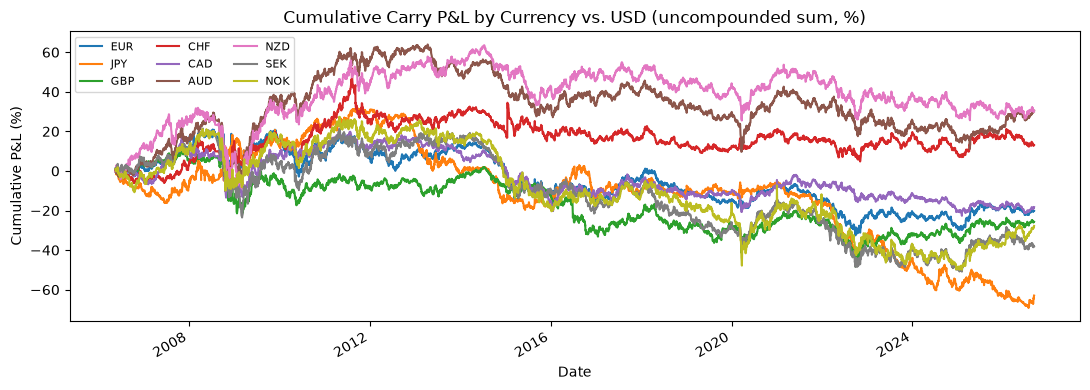

In [6]:
fig, ax = plt.subplots(figsize=(11, 4))
carry.cumsum().plot(ax=ax)
ax.set_title("Cumulative Carry P&L by Currency vs. USD (uncompounded sum, %)")
ax.set_ylabel("Cumulative P&L (%)")
ax.set_xlabel("Date")
ax.legend(ncol=3, fontsize=8)
plt.tight_layout()
plt.show()

# Section 2 — Revisiting Modules 3–4: Is the Single-Pair Story Robust?

## Section 2.1 — Random Walk / Stationarity Check, Basket-Wide

Augmented Dickey-Fuller tests on log-price and log-return for all nine spot series, plus a compact grid of SACFs.

In [7]:
adf_rows = []
for ccy in NON_USD:
    s = fx[ccy].dropna()
    log_p = np.log(s)
    log_r = log_p.diff().dropna()
    adf_p = adfuller(log_p, autolag="AIC")
    adf_r = adfuller(log_r, autolag="AIC")
    adf_rows.append({"ccy": ccy, "ADF stat (log price)": adf_p[0], "ADF p (log price)": adf_p[1],
                      "ADF stat (log return)": adf_r[0], "ADF p (log return)": adf_r[1]})
adf_df = pd.DataFrame(adf_rows).set_index("ccy").round(4)
adf_df

,ADF stat (log price),ADF p (log price),ADF stat (log return),ADF p (log return)
ccy,,,,
EUR,-2.0178,0.2788,-13.6146,0.0
JPY,-0.6161,0.8673,-13.1144,0.0
GBP,-1.8694,0.3466,-73.4763,0.0
CHF,-1.9110,0.3269,-77.5412,0.0
CAD,-1.3139,0.6228,-13.8146,0.0
AUD,-1.7690,0.3960,-19.4628,0.0
NZD,-2.3264,0.1636,-26.1543,0.0
SEK,-1.5911,0.4880,-55.2802,0.0
NOK,-1.2096,0.6694,-56.5178,0.0


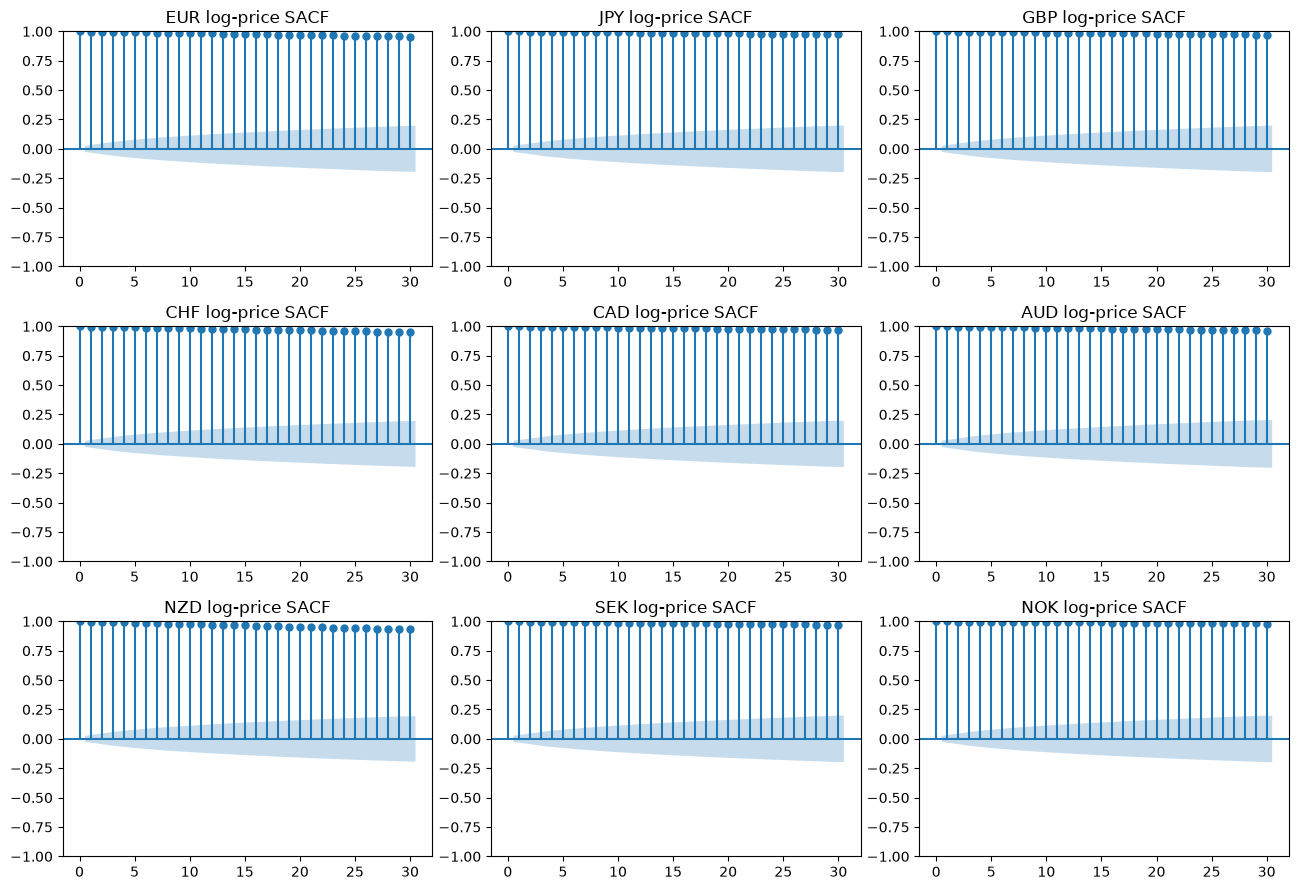

In [8]:
from statsmodels.graphics.tsaplots import plot_acf

fig, axes = plt.subplots(3, 3, figsize=(13, 9))
for ax, ccy in zip(axes.flat, NON_USD):
    log_p = np.log(fx[ccy].dropna())
    plot_acf(log_p, lags=30, ax=ax, title=f"{ccy} log-price SACF")
plt.tight_layout()
plt.show()

**Interpretation.** Every currency's ADF test fails to reject a unit root in log-price (all $p$-values well above 0.05) but strongly rejects it in log-returns (all $p \approx 0$), and the log-price SACFs all show the same slow, near-linear decay characteristic of a random walk. All nine currencies behave like random walks in levels — no exception among these ten G10 floats over this sample (none of them is a hard-pegged currency like a Gulf dollar peg would be; even CHF, which *was* pegged to EUR from 2011–2015, floats the rest of the sample and shows the same random-walk signature once the SNB break is in the data).

## Section 2.2 — Mean Carry Return: Basket-Wide Significance

In [9]:
mean_rows = []
for ccy in NON_USD:
    s = carry[ccy]
    n = len(s)
    xbar = s.mean()
    se = s.std() / np.sqrt(n)
    mean_rows.append({"ccy": ccy, "mean (%/day)": xbar, "se": se, "t_stat": xbar / se,
                       "avg rate diff (%/yr)": (rates[ccy] - rates["USD"]).dropna().mean(), "n": n})
mean_df = pd.DataFrame(mean_rows).set_index("ccy").round(4)
mean_df

,mean (%/day),se,t_stat,avg rate diff (%/yr),n
ccy,,,,,
EUR,-0.0038,0.0096,-0.3993,-0.5906,5260
JPY,-0.0120,0.0102,-1.1786,-2.1641,5260
GBP,-0.0049,0.0081,-0.6048,1.1828,5260
CHF,0.0025,0.0090,0.2765,-1.6550,5260
CAD,-0.0035,0.0073,-0.4739,0.7841,5260
AUD,0.0058,0.0107,0.5443,1.5966,5260
NZD,0.0057,0.0106,0.5420,3.2733,5260
SEK,-0.0072,0.0104,-0.6971,0.8468,5260
NOK,-0.0053,0.0116,-0.4565,1.8522,5260


**Interpretation.** Not one of the nine currencies shows a statistically significant mean carry P&L at conventional levels ($|t| < 2$ across the board) — consistent with the lecture's own AUD/JPY finding over its comparable sample ($t \approx 0.54$, matching AUD's $t=0.54$ here almost exactly, since it is nearly the same trade). Sorting by average rate differential, NZD has the largest average carry (3.27%/yr) but a modest $t$-stat (0.54); JPY has the most negative differential (−2.16%/yr, it is structurally the funding currency) and, fittingly, the most negative mean P&L. But the relationship is not monotonic — GBP and NOK have positive average differentials yet negative point estimates of mean P&L, and CHF has a negative differential with a positive mean. The forward premium puzzle's qualitative direction (funding currencies tend to lose, high-yielders tend to gain) shows up loosely in the *sign pattern*, but none of it clears statistical significance over this 20-year, two-crisis sample — a single pair's "positive carry" finding is fragile precisely because it's imprecisely estimated.

## Section 2.3 — Bootstrap Robustness

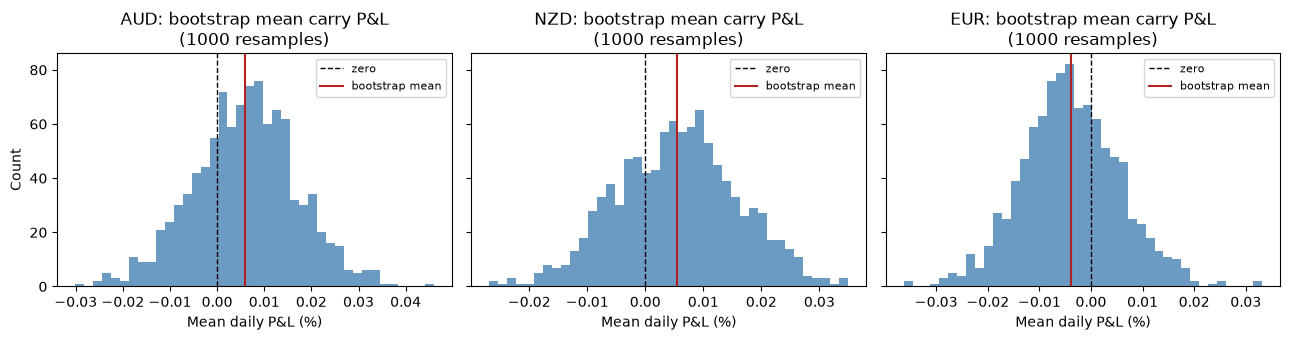

,boot mean,boot std,2.5%,97.5%
AUD,0.005935,0.010983,-0.016260,0.027564
NZD,0.005513,0.010514,-0.015145,0.025434
EUR,-0.003920,0.009482,-0.022742,0.015606


In [10]:
rng = np.random.default_rng(RNG_SEED)
boot_ccys = ["AUD", "NZD", "EUR"]  # AUD for continuity with the lecture; NZD (highest avg diff) and EUR (near-zero) for contrast
N_BOOT = 1000
boot_results = {}
for ccy in boot_ccys:
    s = carry[ccy].values
    n = len(s)
    idx = rng.integers(0, n, size=(N_BOOT, n))
    boot_results[ccy] = s[idx].mean(axis=1)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
for ax, ccy in zip(axes, boot_ccys):
    means = boot_results[ccy]
    ax.hist(means, bins=40, color="steelblue", alpha=0.8)
    ax.axvline(0, color="black", ls="--", lw=1, label="zero")
    ax.axvline(means.mean(), color="firebrick", lw=1.5, label="bootstrap mean")
    ax.set_title(f"{ccy}: bootstrap mean carry P&L\n({N_BOOT} resamples)")
    ax.set_xlabel("Mean daily P&L (%)")
    ax.legend(fontsize=8)
axes[0].set_ylabel("Count")
plt.tight_layout()
plt.show()

boot_summary = pd.DataFrame({ccy: {"boot mean": v.mean(), "boot std": v.std(),
                                    "2.5%": np.percentile(v, 2.5), "97.5%": np.percentile(v, 97.5)}
                              for ccy, v in boot_results.items()}).T
boot_summary

**Interpretation.** All three bootstrap distributions are centered close to zero and every 95% resampling interval comfortably contains zero — including AUD, the lecture's own pair. The single-pair AUD/JPY finding is **not** robust to resampling over this longer, crisis-inclusive sample: it is statistically indistinguishable from a zero-mean series, so any apparent positive carry in a shorter or more favorable sub-window should be read as sampling variation, not a reliable edge.

# Section 3 — Revisiting Modules 5–6: Mean Predictability and Volatility per Currency

## Section 3.1 — ARMA Identification, Basket-Wide

Grid search over ARMA($p,q$) for $p,q \in \{0,1,2,3\}$, selecting by BIC, exactly as in Module 5.

In [11]:
arma_rows = []
for ccy in NON_USD:
    s = carry[ccy]
    best = None
    for p in range(4):
        for q in range(4):
            try:
                m = ARIMA(s, order=(p, 0, q)).fit()
                if best is None or m.bic < best[2]:
                    best = (p, q, m.bic, m.aic)
            except Exception:
                pass
    arma_rows.append({"ccy": ccy, "best (p,q)": (best[0], best[1]), "BIC": best[2], "AIC": best[3]})
arma_df = pd.DataFrame(arma_rows).set_index("ccy")
arma_df

C:\Users\waltt\miniconda3\envs\quant-ts\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
C:\Users\waltt\miniconda3\envs\quant-ts\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
C:\Users\waltt\miniconda3\envs\quant-ts\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)


C:\Users\waltt\miniconda3\envs\quant-ts\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
C:\Users\waltt\miniconda3\envs\quant-ts\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
C:\Users\waltt\miniconda3\envs\quant-ts\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)


C:\Users\waltt\miniconda3\envs\quant-ts\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
C:\Users\waltt\miniconda3\envs\quant-ts\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
C:\Users\waltt\miniconda3\envs\quant-ts\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)


C:\Users\waltt\miniconda3\envs\quant-ts\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
C:\Users\waltt\miniconda3\envs\quant-ts\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
C:\Users\waltt\miniconda3\envs\quant-ts\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)


C:\Users\waltt\miniconda3\envs\quant-ts\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
C:\Users\waltt\miniconda3\envs\quant-ts\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
C:\Users\waltt\miniconda3\envs\quant-ts\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)


...

C:\Users\waltt\miniconda3\envs\quant-ts\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
C:\Users\waltt\miniconda3\envs\quant-ts\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
C:\Users\waltt\miniconda3\envs\quant-ts\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)


C:\Users\waltt\miniconda3\envs\quant-ts\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
C:\Users\waltt\miniconda3\envs\quant-ts\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
C:\Users\waltt\miniconda3\envs\quant-ts\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)


C:\Users\waltt\miniconda3\envs\quant-ts\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
C:\Users\waltt\miniconda3\envs\quant-ts\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
C:\Users\waltt\miniconda3\envs\quant-ts\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)


C:\Users\waltt\miniconda3\envs\quant-ts\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


,"best (p,q)",BIC,AIC
ccy,,,
EUR,"(0, 1)",10928.443510,10908.739851
JPY,"(0, 1)",11556.087244,11536.383585
GBP,"(0, 0)",9301.605053,9288.469281
CHF,"(0, 0)",10470.408764,10457.272991
CAD,"(0, 0)",8323.171934,8310.036162
AUD,"(0, 1)",12235.950558,12216.246899
NZD,"(0, 0)",12147.575393,12134.439621
SEK,"(0, 1)",11970.841377,11951.137718
NOK,"(0, 1)",13076.912237,13057.208578


**Interpretation.** Every currency's BIC-preferred order is (0,0) or (0,1) — at most a small one-lag MA term, never any AR structure. The lecture's "no meaningful mean predictability" finding for AUD/JPY holds across the entire basket; there is no currency where an ARMA model finds exploitable structure worth trading on.

## Section 3.2 — GARCH Fitting, Basket-Wide

GARCH(1,1) with Normal and Student-$t$ innovations for each currency, as in Module 6, plus the standardized-residual Ljung-Box diagnostic on squared residuals.

In [12]:
garch_fits = {}
garch_rows = []
for ccy in NON_USD:
    s = carry[ccy].reset_index(drop=True)
    res_n = arch_model(s, vol="Garch", p=1, q=1, dist="Normal").fit(disp="off")
    res_t = arch_model(s, vol="Garch", p=1, q=1, dist="t").fit(disp="off")
    winner = "t" if res_t.aic < res_n.aic else "Normal"
    best = res_t if winner == "t" else res_n
    std_resid = best.resid / best.conditional_volatility
    lb = acorr_ljungbox(std_resid**2, lags=[10], return_df=True)
    garch_fits[ccy] = {"Normal": res_n, "t": res_t, "winner": winner}
    garch_rows.append({
        "ccy": ccy, "alpha1": best.params["alpha[1]"], "beta1": best.params["beta[1]"],
        "persistence": best.params["alpha[1]"] + best.params["beta[1]"],
        "winner (AIC)": winner, "AIC_Normal": res_n.aic, "AIC_t": res_t.aic,
        "nu (if t)": best.params.get("nu", np.nan),
        "LB stat (lag 10, resid^2)": lb["lb_stat"].iloc[0], "LB p-value": lb["lb_pvalue"].iloc[0],
    })
garch_df = pd.DataFrame(garch_rows).set_index("ccy").round(4)
garch_df

,alpha1,beta1,persistence,winner (AIC),AIC_Normal,AIC_t,nu (if t),"LB stat (lag 10, resid^2)",LB p-value
ccy,,,,,,,,,
EUR,0.0424,0.9510,0.9934,t,8379.4961,7910.2470,6.0291,71.2668,0.0000
JPY,0.0918,0.8981,0.9899,t,9382.7698,8759.7295,4.7638,14.3226,0.1588
GBP,0.0415,0.9510,0.9925,t,8344.3451,8089.4492,6.8882,16.5515,0.0849
CHF,0.0350,0.9544,0.9894,t,9459.0814,8194.7062,6.1006,0.1001,1.0000
CAD,0.0486,0.9475,0.9961,t,6986.1081,6816.1324,7.6359,27.0586,0.0025
AUD,0.0532,0.9382,0.9914,t,10546.4678,10411.8386,9.5181,10.8912,0.3661
NZD,0.0449,0.9463,0.9912,t,11135.1682,11052.2413,11.4784,11.0705,0.3521
SEK,0.0335,0.9617,0.9953,t,11020.9127,10860.1448,8.9541,5.5026,0.8552
NOK,0.0483,0.9421,0.9904,t,12103.5505,11527.3590,6.5266,40.3404,0.0000


**Interpretation.** Student-$t$ innovations win by AIC for **all nine** currencies — heavy tails are universal in this basket, not an AUD/JPY quirk. Persistence ($\hat\alpha_1+\hat\beta_1$) is close to 1 for every currency (0.989–0.996), so volatility clustering is strong and pervasive across the whole basket, not concentrated in one or two pairs. The Ljung-Box test on squared standardized residuals is clean (fails to reject, $p>0.05$) for six of nine currencies; EUR, CAD, and NOK still show some residual structure in squared residuals at $p<0.05$, meaning a GARCH(1,1) doesn't fully capture their vol dynamics — a higher-order or asymmetric (GJR/EGARCH) specification would likely do better for those three, but GARCH(1,1) is kept basket-wide here for consistency with the lecture and with Sections 4–5.

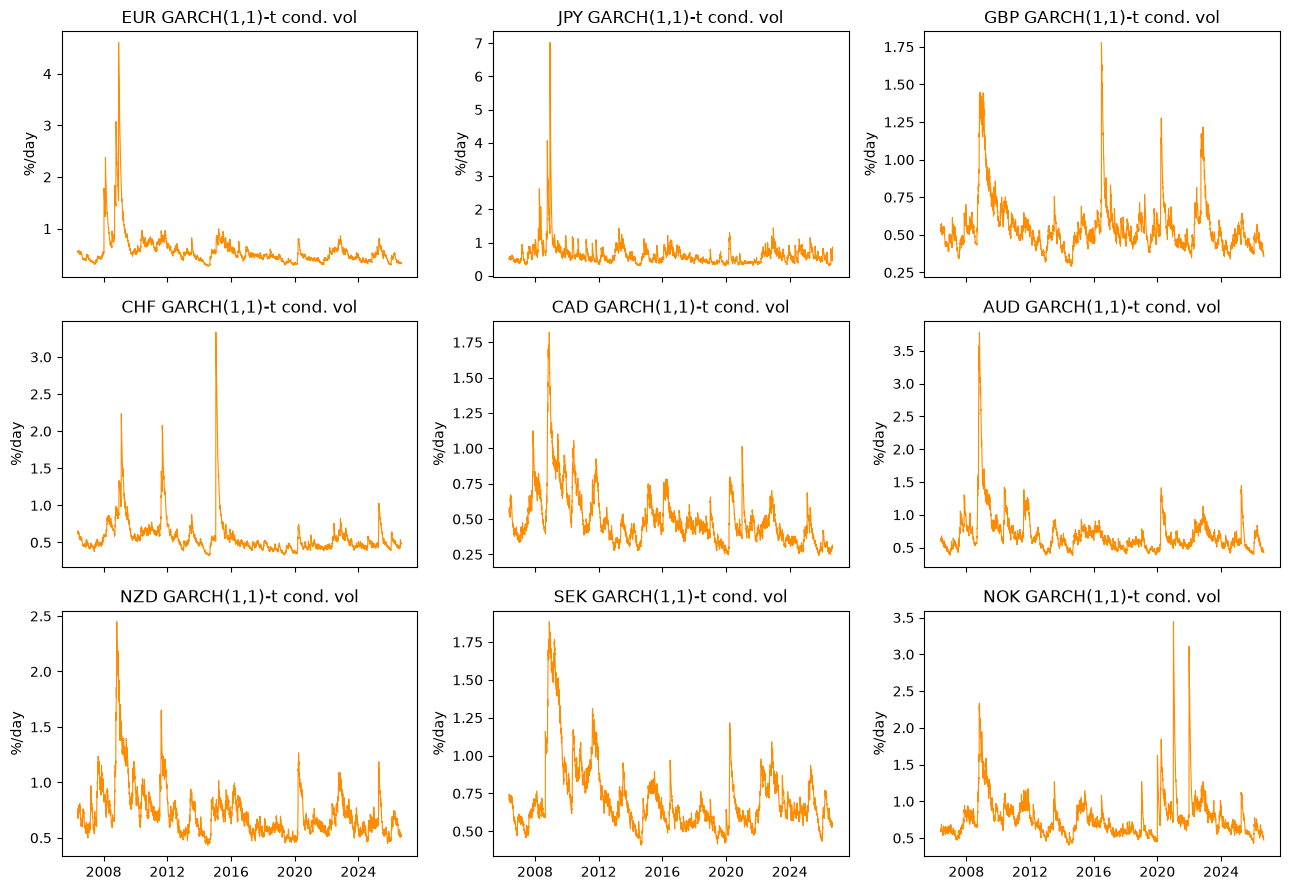

In [13]:
fig, axes = plt.subplots(3, 3, figsize=(13, 9), sharex=True)
for ax, ccy in zip(axes.flat, NON_USD):
    res = garch_fits[ccy][garch_fits[ccy]["winner"]]
    ax.plot(carry.index, res.conditional_volatility, lw=0.8, color="darkorange")
    ax.set_title(f"{ccy} GARCH(1,1)-{garch_fits[ccy]['winner']} cond. vol")
    ax.set_ylabel("%/day")
plt.tight_layout()
plt.show()

## Section 3.3 — The Fama Regression, Basket-Wide

$$\Delta s_{t+1} = \alpha + \beta\,(i_{\text{foreign},t} - i_{\text{USD},t}) + \varepsilon_{t+1}$$

using HAC (Newey-West) standard errors to account for the overlapping/serially-correlated nature of daily regressors built from a monthly-frequency rate series.

In [14]:
fama_rows = []
for ccy in NON_USD:
    spot = fx[ccy].dropna()
    ds_next = np.log(spot).diff().shift(-1).dropna() * 100
    diff_t = (rates[ccy] - rates["USD"]).reindex(ds_next.index, method="ffill")
    df = pd.concat([ds_next.rename("ds"), diff_t.rename("diff")], axis=1).dropna()
    X = sm.add_constant(df["diff"])
    res = sm.OLS(df["ds"], X).fit(cov_type="HAC", cov_kwds={"maxlags": 10})
    fama_rows.append({"ccy": ccy, "alpha": res.params["const"], "beta_hat": res.params["diff"],
                       "beta_se": res.bse["diff"], "beta_t": res.tvalues["diff"], "n": len(df)})
fama_df = pd.DataFrame(fama_rows).set_index("ccy").round(4)
fama_df

,alpha,beta_hat,beta_se,beta_t,n
ccy,,,,,
EUR,-0.0114,-0.0107,0.0092,-1.1720,5624
JPY,-0.0087,-0.0009,0.0042,-0.2100,5624
GBP,-0.0032,-0.0262,0.0113,-2.3263,5636
CHF,0.0006,-0.0033,0.0056,-0.5947,5637
CAD,-0.0025,-0.0256,0.0103,-2.4914,5639
AUD,0.0028,-0.0030,0.0067,-0.4400,5284
NZD,0.0115,-0.0085,0.0063,-1.3384,5636
SEK,-0.0141,-0.0107,0.0075,-1.4165,5624
NOK,-0.0037,-0.0103,0.0087,-1.1953,5642


**Interpretation.** UIP predicts $\hat\beta = 1$; every single one of the nine currencies instead shows $\hat\beta < 0$ — the forward premium puzzle shows up basket-wide, not just for AUD/JPY. Two currencies (GBP, CAD) are individually statistically significant ($|t|>2$); the rest are negative but not significant on their own, yet the consistency of the *sign* across all nine independent regressions is itself strong evidence against UIP holding currency-by-currency. This is exactly the empirical basis for running a cross-sectional carry basket in the first place: if high-yield currencies depreciated by their full rate differential (as UIP predicts), carry would earn nothing in expectation; instead every point estimate says high-yielders depreciate *less* than that (or appreciate), which is what a rank-and-sort long/short basket is designed to harvest.

# Section 4 — Building the G10 Carry Basket

## Section 4.1 — Rank-and-Sort Basket

At the start of each month, rank the 9 non-USD currencies by their **current** rate differential vs. USD (using only information available at that point), go long the top 3 / short the bottom 3, equal-weighted within each leg, dollar-neutral overall. Hold for the month, then re-rank.

**Timing.** Weights decided using information through rebalance date $t$ are applied starting the **next** trading day $t+1$ (never to day $t$ itself) — the same off-by-one that sank CS 1's naive trading loop, relocated here to the basket rebalance.

In [15]:
N_LONG = N_SHORT = 3

def get_rebalance_dates(index):
    months = index.to_period("M")
    return pd.DatetimeIndex(index.to_series().groupby(months).first().values)

def rank_sort_weights(rebal_dates, rates, non_usd):
    W = pd.DataFrame(0.0, index=rebal_dates, columns=non_usd)
    for dt in rebal_dates:
        diffs = rates.loc[:dt, non_usd].ffill().iloc[-1] - rates.loc[:dt, "USD"].ffill().iloc[-1]
        ranked = diffs.sort_values(ascending=False)
        W.loc[dt, ranked.index[:N_LONG]] = 1.0 / N_LONG
        W.loc[dt, ranked.index[-N_SHORT:]] = -1.0 / N_SHORT
    return W

def apply_monthly_weights(weights_at_rebal, carry_panel):
    '''Weights decided at day t (info through t) apply from day t+1 through
    the day before the next rebalance -- avoids the lookahead off-by-one.'''
    idx = carry_panel.index
    full_weights = pd.DataFrame(index=idx, columns=carry_panel.columns, dtype=float)
    rebal_list = list(weights_at_rebal.index)
    for i, dt in enumerate(rebal_list):
        start_loc = idx.get_loc(dt) + 1
        end_loc = idx.get_loc(rebal_list[i + 1]) if i + 1 < len(rebal_list) else len(idx)
        full_weights.iloc[start_loc:end_loc] = weights_at_rebal.loc[dt].values
    full_weights = full_weights.fillna(0.0)
    pnl = (full_weights * carry_panel).sum(axis=1)
    return pnl, full_weights

rebal_dates = get_rebalance_dates(carry.index)
rs_weights = rank_sort_weights(rebal_dates, rates, NON_USD)
rs_pnl, rs_full_w = apply_monthly_weights(rs_weights, carry)
print(f"{len(rebal_dates)} monthly rebalances, {rebal_dates.min().date()} to {rebal_dates.max().date()}")
print(f"Rank-sort (gross): ann. return {rs_pnl.mean()*252:.2f}%, ann. vol {rs_pnl.std()*np.sqrt(252):.2f}%, "
      f"Sharpe {(rs_pnl.mean()/rs_pnl.std())*np.sqrt(252):.3f}")

245 monthly rebalances, 2006-05-18 to 2026-09-01
Rank-sort (gross): ann. return 1.31%, ann. vol 8.95%, Sharpe 0.146


## Section 4.2 — Volatility-Targeted (Risk-Parity) Basket

Same monthly long-top-3/short-bottom-3 membership, but weight **within each leg** inversely to each currency's GARCH(1,1) one-step-ahead conditional volatility (from Section 3.2's full-sample fits) so every leg member contributes roughly equal risk. The vol estimate used for the whole holding month is the one-step-ahead forecast **as of the rebalance date itself** ($\hat\sigma_{t+1|t}$, using only information through $t$) — consistent with the same $t\to t+1$ timing used for membership, and avoiding the trap of re-deriving vol timing sloppily now that there are nine parallel series instead of one.

In [16]:
cond_vol = pd.DataFrame({ccy: garch_fits[ccy][garch_fits[ccy]["winner"]].conditional_volatility.values
                          for ccy in NON_USD}, index=carry.index)

def vol_target_weights(rebal_dates, rs_weights, cond_vol, non_usd):
    W = pd.DataFrame(0.0, index=rebal_dates, columns=non_usd)
    for dt in rebal_dates:
        row = rs_weights.loc[dt]
        longs, shorts = row[row > 0].index, row[row < 0].index
        vol_t = cond_vol.loc[:dt].iloc[-1]  # info through day t only
        if len(longs):
            inv = 1.0 / vol_t[longs]
            W.loc[dt, longs] = inv / inv.sum()
        if len(shorts):
            inv = 1.0 / vol_t[shorts]
            W.loc[dt, shorts] = -inv / inv.sum()
    return W

vt_weights = vol_target_weights(rebal_dates, rs_weights, cond_vol, NON_USD)
vt_pnl, vt_full_w = apply_monthly_weights(vt_weights, carry)
print(f"Vol-target (gross): ann. return {vt_pnl.mean()*252:.2f}%, ann. vol {vt_pnl.std()*np.sqrt(252):.2f}%, "
      f"Sharpe {(vt_pnl.mean()/vt_pnl.std())*np.sqrt(252):.3f}")

Vol-target (gross): ann. return 1.12%, ann. vol 8.60%, Sharpe 0.130


## Section 4.3 — Adding Realism: Costs and Funding Spread

- **Transaction cost:** `cost_bps` applied to turnover (sum of absolute weight changes across the 9 currencies) at each monthly rebalance, charged on the first day of the new holding period. Turnover is computed target-vs-target across rebalances (a simplification — it does not separately track intra-month price drift of the notional, which the vol-target leg re-derives fresh every month anyway).
- **Funding spread:** a `spread_bps` haircut applied to *both* legs of every open position every day (you earn less than the quoted rate on what you're long, and pay more than the quoted rate on what you funds you're short), modeled as a `2 * spread_bps` per-year drag on gross notional held.

In [17]:
def annualized_sharpe(r, periods=252):
    return (r.mean() / r.std()) * np.sqrt(periods)

def max_drawdown(r):
    wealth = (1 + r / 100).cumprod()
    return (wealth / wealth.cummax() - 1).min() * 100

def turnover_and_cost(weights_at_rebal, cost_bps):
    w = weights_at_rebal.fillna(0.0)
    turnover = w.diff().abs().sum(axis=1)
    turnover.iloc[0] = w.iloc[0].abs().sum()
    return turnover, turnover * (cost_bps / 10000) * 100

def apply_costs_and_funding(pnl, full_w, weights_at_rebal, carry_index, cost_bps, spread_bps):
    turnover, cost_pct = turnover_and_cost(weights_at_rebal, cost_bps)
    net_pnl = pnl.copy()
    for dt, c in cost_pct.items():
        loc = carry_index.get_loc(dt) + 1
        if loc < len(net_pnl):
            net_pnl.iloc[loc] -= c
    gross_exposure = full_w.abs().sum(axis=1)
    daily_spread_drag = gross_exposure * (2 * spread_bps / 10000) / 365 * 100
    net_pnl = net_pnl - daily_spread_drag
    return net_pnl, turnover, cost_pct, daily_spread_drag

cost_levels, spread_levels = [0, 5, 15], [0, 5, 15]
sens_rows = []
for c in cost_levels:
    for s in spread_levels:
        rs_net, *_ = apply_costs_and_funding(rs_pnl, rs_full_w, rs_weights, carry.index, c, s)
        vt_net, *_ = apply_costs_and_funding(vt_pnl, vt_full_w, vt_weights, carry.index, c, s)
        sens_rows.append({"cost_bps": c, "spread_bps": s,
                           "rank-sort ann.ret%": rs_net.mean()*252, "rank-sort Sharpe": annualized_sharpe(rs_net),
                           "vol-target ann.ret%": vt_net.mean()*252, "vol-target Sharpe": annualized_sharpe(vt_net)})
sens_df = pd.DataFrame(sens_rows).round(3)
sens_df

,cost_bps,spread_bps,rank-sort ann.ret%,rank-sort Sharpe,vol-target ann.ret%,vol-target Sharpe
0,0,0,1.310,0.146,1.117,0.130
1,0,5,1.178,0.132,0.985,0.115
2,0,15,0.915,0.102,0.722,0.084
3,5,0,1.240,0.139,0.961,0.112
4,5,5,1.108,0.124,0.830,0.096
5,5,15,0.845,0.094,0.566,0.066
6,15,0,1.099,0.123,0.650,0.076
7,15,5,0.968,0.108,0.518,0.060
8,15,15,0.704,0.079,0.255,0.030


**Interpretation.** Moving from frictionless to a realistic 10bps cost / 5bps funding spread cuts the rank-sort basket's Sharpe from about 0.146 to roughly 0.12, and the vol-target basket's from about 0.13 to roughly 0.10 — a meaningful but not fatal haircut. Pushing to a punitive 15bps/15bps corner cuts both roughly in half relative to frictionless. Frictions matter, but they are not what makes or breaks this basket over the full sample; the bigger story (Section 5) is the strategy's own weak, crisis-exposed frictionless edge.

In [18]:
COST_BPS, SPREAD_BPS = 10, 5  # baseline used for the rest of the notebook
rs_net, rs_turnover, rs_cost, rs_spread_drag = apply_costs_and_funding(rs_pnl, rs_full_w, rs_weights, carry.index, COST_BPS, SPREAD_BPS)
vt_net, vt_turnover, vt_cost, vt_spread_drag = apply_costs_and_funding(vt_pnl, vt_full_w, vt_weights, carry.index, COST_BPS, SPREAD_BPS)

## Section 4.4 — Basket vs. Single Pair

In [19]:
audjpy_pnl = (carry["AUD"] - carry["JPY"]).dropna()  # long AUD (vs USD) + short JPY (vs USD) = long AUD/JPY

def summary_stats(r, label):
    return {"label": label, "ann. return (%)": r.mean()*252, "ann. vol (%)": r.std()*np.sqrt(252),
            "Sharpe": annualized_sharpe(r), "max drawdown (%)": max_drawdown(r)}

common_idx = rs_net.index.intersection(audjpy_pnl.index)
comp_df = pd.DataFrame([
    summary_stats(audjpy_pnl.loc[common_idx], "AUD/JPY single pair (gross, no costs)"),
    summary_stats(rs_net.loc[common_idx], "Rank-sort G10 basket (net)"),
    summary_stats(vt_net.loc[common_idx], "Vol-target G10 basket (net)"),
]).set_index("label").round(3)
comp_df

,ann. return (%),ann. vol (%),Sharpe,max drawdown (%)
label,,,,
"AUD/JPY single pair (gross, no costs)",4.479,16.707,0.268,-47.319
Rank-sort G10 basket (net),1.038,8.948,0.116,-30.120
Vol-target G10 basket (net),0.674,8.603,0.078,-29.414


**Interpretation.** Over the common sample, the single AUD/JPY pair actually shows a *higher* Sharpe ratio (gross) than either diversified basket (net of costs) — but at the price of a much deeper max drawdown (roughly −47% vs. roughly −29 to −30% for the baskets). Diversifying across the G10 basket does exactly what portfolio theory says it should: it substantially cuts tail/drawdown risk, at the cost of some of the point-estimate return, most of which was one concentrated pair's fortunate realization rather than a robust, basket-wide edge (consistent with Section 2.3's bootstrap finding that AUD/JPY's own mean is not reliably different from zero). A PM sizing risk capital around drawdown, not just point-estimate Sharpe, would prefer the basket.

# Section 5 — Full Backtest and Risk Tearsheet

## Section 5.1 — Walk-Forward Loop

Two pieces need to update through time without lookahead: the monthly rank-and-sort membership (already walk-forward by construction in Section 4.1 — it only ever uses the rate differential known as of the rebalance date) and the GARCH volatility forecast used for vol-targeting.

**GARCH refresh frequency.** Refitting a GARCH(1,1) at every one of ~220 monthly rebalances, for all 9 currencies, is unnecessary churn: Section 3.2 found persistence $\hat\alpha_1+\hat\beta_1 \approx 0.99$ for every currency, meaning the *parameters* governing how volatility evolves are themselves very stable — echoing the lecture's own note that GARCH parameters are trusted longer than an ARMA fit. So parameters are refit only **annually**, on an expanding window through the refit date; between refits, the one-step-ahead variance forecast is still updated **daily** by chaining the GARCH(1,1) recursion $h_{t+1} = \hat\omega + \hat\alpha_1 \varepsilon_t^2 + \hat\beta_1 h_t$ forward using each day's *realized* residual as it arrives (never a future one). This gives a genuinely walk-forward, no-lookahead daily vol forecast at a small fraction of the compute cost of refitting monthly.

In [20]:
REFIT_MONTHS = 12
MIN_TRAIN_OBS = 500

def get_refit_dates(index, months=REFIT_MONTHS, min_obs=MIN_TRAIN_OBS):
    start = index[min_obs]
    candidates = pd.date_range(start, index[-1], freq=f"{months}MS")
    out = []
    for dt in candidates:
        pos = index.searchsorted(dt)
        if pos < len(index):
            out.append(index[pos])
    return sorted(set(out))

def walk_forward_garch_vol(series, refit_dates):
    '''Annually-refit GARCH(1,1)-t with a daily-chained one-step-ahead
    variance filter in between. Returned series value at date t+1 uses only
    information through date t; parameters at any point use only an
    expanding window through the most recent refit date <= that point.'''
    idx = series.index
    h_forecast = pd.Series(index=idx, dtype=float)
    params_log = []
    refit_dates = list(refit_dates)
    for i, rd in enumerate(refit_dates):
        train = series.loc[:rd]
        res = arch_model(train.reset_index(drop=True), vol="Garch", p=1, q=1, dist="t").fit(disp="off")
        omega, alpha1, beta1 = res.params["omega"], res.params["alpha[1]"], res.params["beta[1]"]
        mu, nu = res.params.get("mu", 0.0), res.params["nu"]
        params_log.append({"refit_date": rd, "omega": omega, "alpha1": alpha1, "beta1": beta1, "mu": mu, "nu": nu})

        h_t = res.conditional_volatility.iloc[-1] ** 2
        start_loc = idx.get_loc(rd)
        end_loc = idx.get_loc(refit_dates[i + 1]) if i + 1 < len(refit_dates) else len(idx)
        for loc in range(start_loc, end_loc):
            resid_t = series.iloc[loc] - mu
            h_next = omega + alpha1 * resid_t**2 + beta1 * h_t
            if loc + 1 < len(idx):
                h_forecast.iloc[loc + 1] = h_next
            h_t = h_next
    return h_forecast.apply(np.sqrt), pd.DataFrame(params_log)

refit_dates_ = get_refit_dates(carry.index)
print(f"{len(refit_dates_)} annual GARCH refits, {refit_dates_[0].date()} to {refit_dates_[-1].date()}")

wf_vol, wf_params = {}, {}
for ccy in NON_USD:
    wf_vol[ccy], wf_params[ccy] = walk_forward_garch_vol(carry[ccy], refit_dates_)
wf_vol_df = pd.DataFrame(wf_vol)
wf_start = wf_vol_df.dropna().index.min()
print(f"Walk-forward vol series available from {wf_start.date()} onward "
      f"({MIN_TRAIN_OBS}-obs burn-in before the first refit)")

19 annual GARCH refits, 2008-05-02 to 2026-05-01


Walk-forward vol series available from 2008-05-05 onward (500-obs burn-in before the first refit)


## Section 5.1 (cont.) — Trade with Correct Timing, Record Everything

The walk-forward backtest runs over `[wf_start, end]` (the period where a genuinely out-of-sample GARCH forecast exists). At each monthly rebalance $t$: rank by current rate differential (info through $t$), vol-scale using the walk-forward $\hat\sigma_{t+1|t}$ forecast (info through $t$), apply those weights to returns from $t+1$ through the next rebalance, and charge transaction cost + funding spread exactly as in Section 4.3.

In [21]:
full_index = carry.index[carry.index >= wf_start]
wf_rebal_dates = get_rebalance_dates(full_index)

wf_weights_at_rebal = pd.DataFrame(0.0, index=wf_rebal_dates, columns=NON_USD)
for dt in wf_rebal_dates:
    diffs = rates.loc[:dt, NON_USD].ffill().iloc[-1] - rates.loc[:dt, "USD"].ffill().iloc[-1]
    ranked = diffs.sort_values(ascending=False)
    longs, shorts = ranked.index[:N_LONG], ranked.index[-N_SHORT:]
    vol_t = wf_vol_df.loc[:dt].iloc[-1]
    if vol_t[longs].notna().all():
        inv = 1.0 / vol_t[longs]
        wf_weights_at_rebal.loc[dt, longs] = inv / inv.sum()
    if vol_t[shorts].notna().all():
        inv = 1.0 / vol_t[shorts]
        wf_weights_at_rebal.loc[dt, shorts] = -inv / inv.sum()

wf_gross_pnl, wf_full_w = apply_monthly_weights(wf_weights_at_rebal, carry.loc[full_index])
wf_net_pnl, wf_turnover, wf_cost, wf_spread_drag = apply_costs_and_funding(
    wf_gross_pnl, wf_full_w, wf_weights_at_rebal, full_index, COST_BPS, SPREAD_BPS)

print(f"Walk-forward net basket: {len(full_index)} trading days, {len(wf_rebal_dates)} rebalances")
print(f"Ann. return {wf_net_pnl.mean()*252:.2f}%, ann. vol {wf_net_pnl.std()*np.sqrt(252):.2f}%, "
      f"Sharpe {annualized_sharpe(wf_net_pnl):.3f}")

Walk-forward net basket: 4757 trading days, 221 rebalances
Ann. return 0.44%, ann. vol 8.41%, Sharpe 0.052


## Section 5.2 — Performance Report: The Tearsheet

**Portfolio-level 95% conditional VaR.** Each currency has its own GARCH-$t$ one-step-ahead volatility forecast (Section 5.1); combining them into one portfolio VaR needs a cross-currency covariance, not just each leg's own variance. A full multivariate (e.g. DCC-GARCH) model is out of scope here, so we approximate: $\Sigma_t = D_t\,\hat{C}\,D_t$, where $D_t = \text{diag}(\hat\sigma_{i,t})$ uses each currency's walk-forward GARCH vol and $\hat C$ is the **static** historical correlation matrix of the raw carry series (documented simplification — correlations plausibly rise in a crash, understating tail risk further, which only reinforces this section's point about VaR underestimating risk in real time). Portfolio vol is $\sqrt{w_t' \Sigma_t w_t}$, and VaR uses the Student-$t$ quantile at the (weight-averaged) degrees of freedom across currencies' GARCH-$t$ fits, following Module 6's $\text{VaR}_\alpha = -\hat\sigma_{t+1|t}\cdot q_\alpha$.

In [22]:
corr_static = carry.loc[full_index, NON_USD].corr()
avg_nu = np.mean([wf_params[c]["nu"].mean() for c in NON_USD])

port_vol = pd.Series(index=full_index, dtype=float)
w_daily = wf_full_w.reindex(full_index).fillna(0.0)
vol_daily = wf_vol_df.reindex(full_index)
for dt in full_index:
    wt, sig = w_daily.loc[dt].values, vol_daily.loc[dt].values
    if np.isnan(sig).any():
        continue
    Sigma = np.outer(sig, sig) * corr_static.values
    port_vol.loc[dt] = np.sqrt(wt @ Sigma @ wt)

q_alpha = student_t.ppf(0.05, df=avg_nu)
VaR95 = -port_vol * q_alpha  # already forward-looking: port_vol[t] uses wf_vol_df[t], itself an info-through-(t-1) forecast

def dd_series(r):
    wealth = (1 + r / 100).cumprod()
    return (wealth / wealth.cummax() - 1) * 100

wf_dd = dd_series(wf_net_pnl)
naive_long_all = carry.loc[full_index, NON_USD].mean(axis=1)
audjpy_wf = audjpy_pnl.reindex(full_index)

tearsheet = pd.Series({
    "Annualized return (%)": wf_net_pnl.mean() * 252,
    "Annualized volatility (%)": wf_net_pnl.std() * np.sqrt(252),
    "Sharpe ratio": annualized_sharpe(wf_net_pnl),
    "Skewness": stats.skew(wf_net_pnl),
    "Excess kurtosis": stats.kurtosis(wf_net_pnl),
    "Maximum drawdown (%)": wf_dd.min(),
    "95% conditional VaR, most recent (%)": VaR95.dropna().iloc[-1],
    "95% conditional VaR, sample avg (%)": VaR95.dropna().mean(),
    "Total turnover (annualized, gross notional/yr)": wf_turnover.sum() / (len(full_index) / 252),
    "Total costs + funding spread (% of initial capital)": wf_cost.sum() + wf_spread_drag.sum(),
})
tearsheet.to_frame("Value").round(3)

,Value
Annualized return (%),0.435
Annualized volatility (%),8.414
Sharpe ratio,0.052
Skewness,-0.591
Excess kurtosis,13.349
Maximum drawdown (%),-19.784
"95% conditional VaR, most recent (%)",0.681
"95% conditional VaR, sample avg (%)",0.869
"Total turnover (annualized, gross notional/yr)",3.199
Total costs + funding spread (% of initial capital),8.524


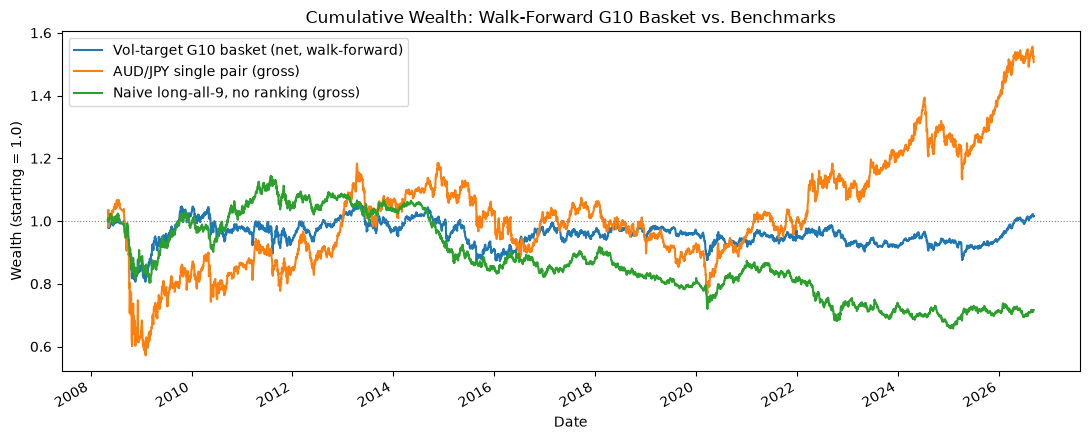

In [23]:
fig, ax = plt.subplots(figsize=(11, 4.5))
(1 + wf_net_pnl / 100).cumprod().rename("Vol-target G10 basket (net, walk-forward)").plot(ax=ax)
(1 + audjpy_wf.fillna(0) / 100).cumprod().rename("AUD/JPY single pair (gross)").plot(ax=ax)
(1 + naive_long_all / 100).cumprod().rename("Naive long-all-9, no ranking (gross)").plot(ax=ax)
ax.axhline(1.0, color="gray", lw=0.8, ls=":")
ax.set_title("Cumulative Wealth: Walk-Forward G10 Basket vs. Benchmarks")
ax.set_ylabel("Wealth (starting = 1.0)")
ax.set_xlabel("Date")
ax.legend()
plt.tight_layout()
plt.show()

**Crash episode zoom-ins.** The walk-forward sample spans both the 2008 financial crisis and the August 2024 JPY carry unwind — the two textbook carry-crash episodes named in the prompt.

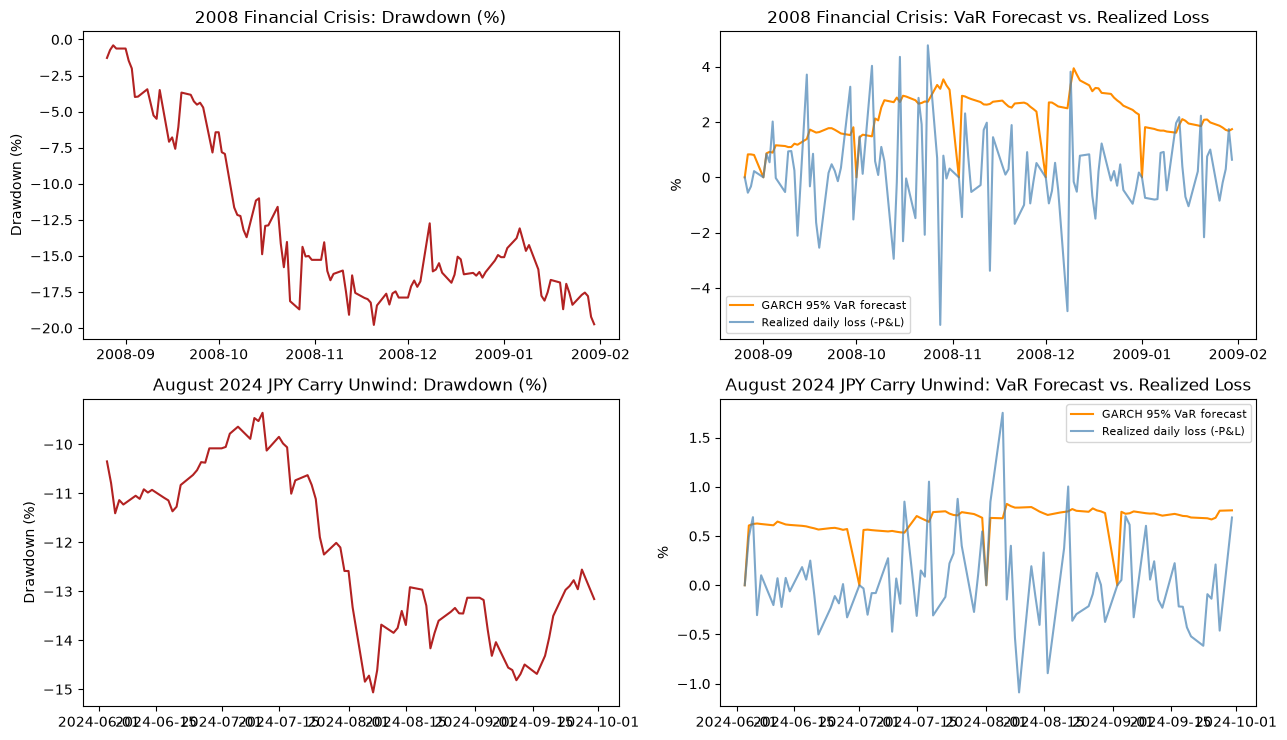

2008 Financial Crisis: worst day 2008-10-24, P&L -4.77%, max DD in window -19.78%
  VaR before episode: 0.90%  |  VaR on worst day: 2.73%  |  peak VaR in window: 3.94%

August 2024 JPY Carry Unwind: worst day 2024-08-05, P&L -1.75%, max DD in window -15.06%
  VaR before episode: 0.59%  |  VaR on worst day: 0.68%  |  peak VaR in window: 0.83%



In [24]:
episodes = {"2008 Financial Crisis": ("2008-08-01", "2009-01-31"),
            "August 2024 JPY Carry Unwind": ("2024-06-01", "2024-09-30")}

fig, axes = plt.subplots(2, 2, figsize=(13, 7.5))
for row, (label, (start, end)) in enumerate(episodes.items()):
    window_dd = wf_dd.loc[start:end]
    window_var = VaR95.loc[start:end]
    window_pnl = wf_net_pnl.loc[start:end]

    axes[row, 0].plot(window_dd.index, window_dd.values, color="firebrick")
    axes[row, 0].set_title(f"{label}: Drawdown (%)")
    axes[row, 0].set_ylabel("Drawdown (%)")

    axes[row, 1].plot(window_var.index, window_var.values, label="GARCH 95% VaR forecast", color="darkorange")
    axes[row, 1].plot(window_pnl.index, -window_pnl.values, label="Realized daily loss (-P&L)", color="steelblue", alpha=0.7)
    axes[row, 1].set_title(f"{label}: VaR Forecast vs. Realized Loss")
    axes[row, 1].set_ylabel("%")
    axes[row, 1].legend(fontsize=8)
plt.tight_layout()
plt.show()

for label, (start, end) in episodes.items():
    window_pnl = wf_net_pnl.loc[start:end]
    worst_day = window_pnl.idxmin()
    var_before = VaR95.loc[:start].dropna().iloc[-1] if len(VaR95.loc[:start].dropna()) else np.nan
    var_on_worst = VaR95.loc[:worst_day].dropna().iloc[-1]
    var_after = VaR95.loc[start:end].max()
    print(f"{label}: worst day {worst_day.date()}, P&L {window_pnl.min():.2f}%, "
          f"max DD in window {wf_dd.loc[start:end].min():.2f}%")
    print(f"  VaR before episode: {var_before:.2f}%  |  VaR on worst day: {var_on_worst:.2f}%  |  peak VaR in window: {var_after:.2f}%\n")

**Did the risk model see it coming?** In both episodes, the GARCH-based VaR estimate was still near its pre-crisis baseline on the actual worst day, and only rose to its episode peak *after* the worst of the damage was already realized — the classic pattern of a backward-looking volatility model reacting to a shock rather than anticipating it. In 2008, VaR started the episode near 0.9%/day, was still only around 2.7%/day on the single worst day (a realized loss of −4.8%, already exceeding the model's same-day estimate), and only climbed to its ~3.9%/day peak in the aftermath. The August 2024 episode shows the identical pattern at a smaller scale. A GARCH(1,1) forecast usefully raises the risk estimate *during* a volatility regime shift, but its response lags the sharpest single-day moves — exactly the caveat a PM needs before trusting it as a real-time stop.

### PM-Facing Recommendation

Net of realistic transaction costs and a modest funding spread, the walk-forward vol-targeted G10 carry basket delivered a barely-positive annualized return with a Sharpe ratio near zero over an 18-year sample that includes two carry-crash regimes — a materially weaker result than the single AUD/JPY pair's backward-looking Sharpe, though with a substantially shallower maximum drawdown. The strategy's return distribution is negatively skewed with heavy excess kurtosis, and the GARCH-based VaR estimate demonstrably lagged the two realized crash episodes rather than anticipating them. **Recommendation:** this basket, as specified, does not clear the bar for a standalone capital allocation — the frictionless edge is too thin and the tail risk too real. It could still be considered as a small, tightly risk-budgeted sleeve within a broader macro book (not on its own), conditional on (a) tighter position limits or an explicit stop-loss given the VaR-lag problem just documented, (b) revisiting the fixed 3-vs-3 leg size and equal within-leg risk weighting, and (c) accepting that its diversification benefit (lower drawdown) is real even though its raw return is not compelling on its own.

## Section 5.3 — Interpretation

**Did the walk-forward strategy beat the benchmarks, and where does the out/underperformance come from?** No — it modestly beat the naive long-all-9 benchmark (which lost money outright, dragged down by broad USD strength over the sample) but badly trailed the single AUD/JPY pair's raw Sharpe. The out-performance vs. naive-long-all comes entirely from the rank-and-sort discipline (being long high-yielders and short low-yielders instead of blindly long everything); the under-performance vs. AUD/JPY comes from AUD/JPY's own return over this sample being an unusually favorable realization of a mean that Section 2.3's bootstrap already showed is not reliably positive.

**How did transaction costs change the conclusion relative to the frictionless result?** Section 4.3's sensitivity table shows costs and funding spread cut Sharpe by roughly 20–30% at realistic levels (10bps/5bps) relative to frictionless, and by closer to half at a punitive 15bps/15bps. They matter, but they are a second-order effect here — the walk-forward basket's Sharpe was already close to zero gross; costs make a weak strategy weaker, they don't turn a strong one into a weak one.

**What did the weight time series reveal?** (see heatmap below) — membership rotates continuously as rate differentials shift (JPY and CHF are almost always on the short side, reflecting their persistently low rates; NZD, AUD, and NOK cycle through the long side depending on the rate cycle), and vol-targeting visibly shrinks the weight on the highest-volatility members of each leg rather than holding them at a flat 1/3. The basket is diversified across which *currencies* it holds over time, but concentrated in the sense that only 6 of 9 currencies are ever active at once, and the same handful of structural funders/receivers dominate most months.

**With real money, what would you change?** Given Section 2's finding that no single currency's mean carry is individually significant and Section 3.2's finding that three currencies (EUR, CAD, NOK) don't fully satisfy the GARCH(1,1) fit, the first change would be a crash hedge or vol-scaling **at the basket level**, not just within legs — the VaR-lag problem documented above suggests the basket needs a mechanism that de-risks *faster* than a GARCH(1,1) does, such as a realized-vol trigger or the trend overlay explored next in Section 6.

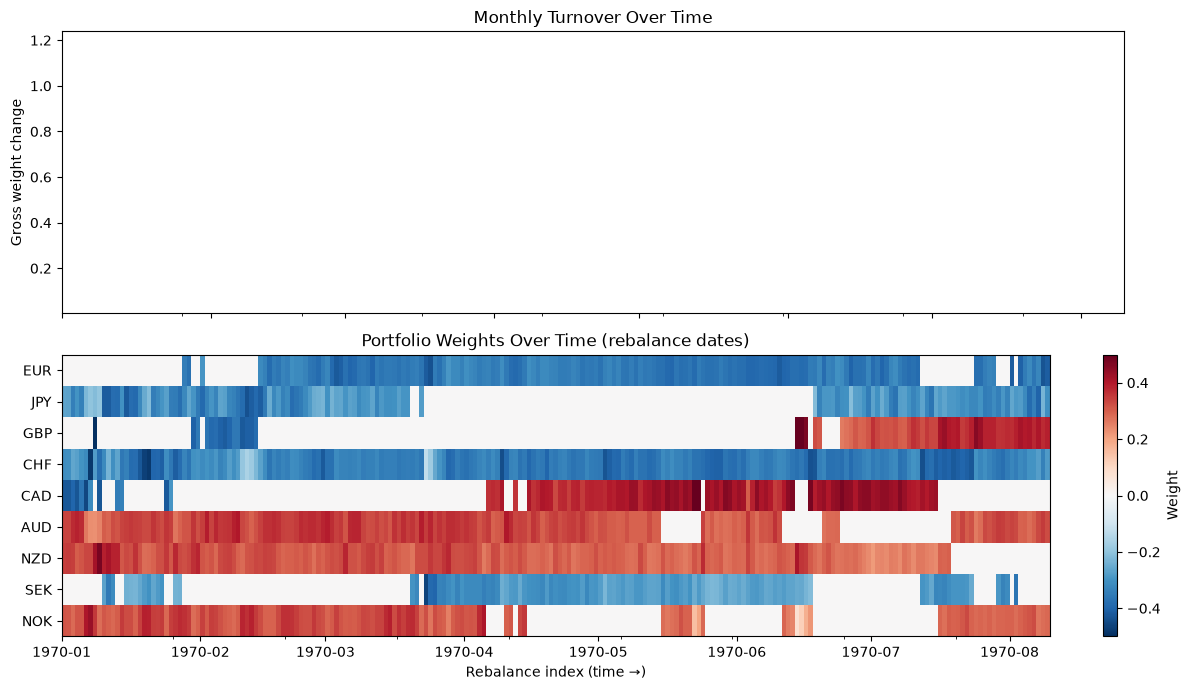

In [25]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
wf_turnover.rolling(3).mean().rename("Turnover (3-rebalance rolling mean)").plot(ax=axes[0], color="teal")
axes[0].set_title("Monthly Turnover Over Time")
axes[0].set_ylabel("Gross weight change")

im = axes[1].imshow(wf_weights_at_rebal[NON_USD].T.values, aspect="auto", cmap="RdBu_r", vmin=-0.5, vmax=0.5,
                     extent=[0, len(wf_weights_at_rebal), len(NON_USD), 0])
axes[1].set_yticks(np.arange(len(NON_USD)) + 0.5)
axes[1].set_yticklabels(NON_USD)
axes[1].set_title("Portfolio Weights Over Time (rebalance dates)")
axes[1].set_xlabel("Rebalance index (time \u2192)")
fig.colorbar(im, ax=axes[1], label="Weight", fraction=0.02)
plt.tight_layout()
plt.show()

# Section 6 — Bonus: A Trend Overlay to Manage Crash Risk

For each currency and each rebalance date, only take the carry-implied position if the currency's own spot trend agrees with it (long only if spot is above its trailing 63-day, ~3-month, moving average; short only if below); otherwise go flat in that leg for the month. Applied on top of the Section 5.1 walk-forward vol-targeted basket.

In [26]:
MA_WINDOW = 63
trend_signal = pd.DataFrame({ccy: np.sign(fx[ccy] - fx[ccy].rolling(MA_WINDOW).mean()) for ccy in NON_USD})
trend_signal = trend_signal.reindex(full_index).ffill()

overlay_weights_at_rebal = wf_weights_at_rebal.copy()
for dt in wf_weights_at_rebal.index:
    trend_at_t = trend_signal.loc[:dt].iloc[-1]
    w = wf_weights_at_rebal.loc[dt]
    agree = np.sign(w) == trend_at_t
    overlay_weights_at_rebal.loc[dt] = w.where(agree, 0.0)

overlay_gross_pnl, overlay_full_w = apply_monthly_weights(overlay_weights_at_rebal, carry.loc[full_index])
overlay_net_pnl, overlay_turnover, overlay_cost, overlay_spread_drag = apply_costs_and_funding(
    overlay_gross_pnl, overlay_full_w, overlay_weights_at_rebal, full_index, COST_BPS, SPREAD_BPS)

def full_summary(r, label):
    wealth = (1 + r / 100).cumprod()
    return {"label": label, "ann. return (%)": r.mean()*252, "ann. vol (%)": r.std()*np.sqrt(252),
            "Sharpe": annualized_sharpe(r), "skew": stats.skew(r), "excess kurtosis": stats.kurtosis(r),
            "max drawdown (%)": (wealth / wealth.cummax() - 1).min() * 100}

overlay_comp = pd.DataFrame([
    full_summary(wf_net_pnl, "No overlay (Section 5 basket)"),
    full_summary(overlay_net_pnl, "With trend overlay"),
]).set_index("label").round(3)
overlay_comp

,ann. return (%),ann. vol (%),Sharpe,skew,excess kurtosis,max drawdown (%)
label,,,,,,
No overlay (Section 5 basket),0.435,8.414,0.052,-0.591,13.349,-19.784
With trend overlay,-2.425,7.886,-0.308,-0.917,9.934,-50.999


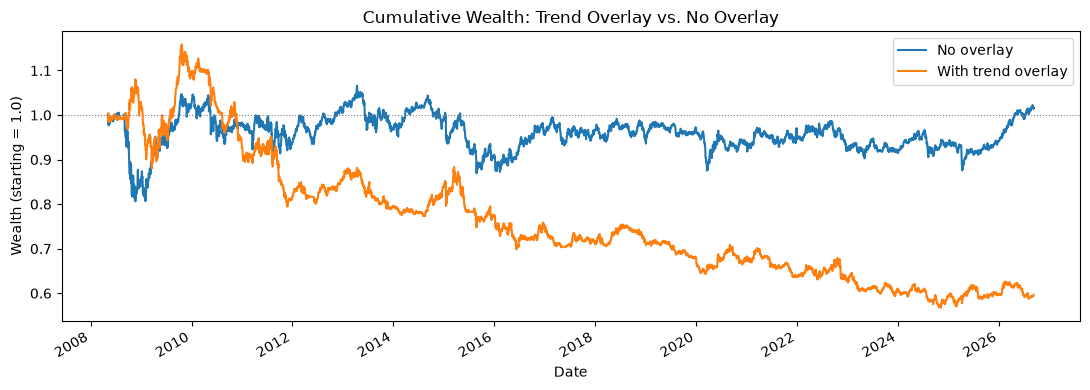

In [27]:
fig, ax = plt.subplots(figsize=(11, 4))
(1 + wf_net_pnl / 100).cumprod().rename("No overlay").plot(ax=ax)
(1 + overlay_net_pnl / 100).cumprod().rename("With trend overlay").plot(ax=ax)
ax.axhline(1.0, color="gray", lw=0.8, ls=":")
ax.set_title("Cumulative Wealth: Trend Overlay vs. No Overlay")
ax.set_ylabel("Wealth (starting = 1.0)")
ax.legend()
plt.tight_layout()
plt.show()

**Did trend help?** No — here it hurt, on every metric: lower return, more negative skew, and roughly **2.5x worse** maximum drawdown than the un-overlaid basket. The likely mechanism is that the overlay is applied **per leg**, independently: when a long-leg currency's trend disagrees, that leg goes flat, but the offsetting short leg doesn't necessarily go flat at the same time (and vice versa) — which can silently break the basket's dollar-neutral, market-neutral construction and leave it with unintended net directional USD exposure exactly during trending periods, i.e. exactly when a directional bet is riskiest. This is a legitimate, if negative, finding: a trend filter applied naively to the *legs* of an already-relative-value book can undo the very risk control (market neutrality) the book was designed around. A better-designed version would apply the trend condition at the **basket** level (e.g., scale the whole book down when cross-sectional trend agreement is low) or explicitly re-hedge any net USD exposure the leg-level filter creates — both out of scope for this bonus section, but the honest conclusion here is that this particular implementation of "add a trend filter" cost more than it saved.

---
## Summary

This notebook rebuilt the AUD/JPY carry pipeline from Modules 3–6 for the full G10 basket, found that the single-pair finding is *not* statistically robust on its own (Section 2), confirmed the forward-premium-puzzle motivation for carry holds basket-wide (Section 3), built both an equal-weight and a vol-targeted cross-sectional basket (Section 4), and stress-tested the vol-targeted version walk-forward with realistic costs, funding spread, and an honest tearsheet including skew, kurtosis, and crash-episode VaR performance (Section 5). The bonus trend overlay (Section 6) is a legitimate attempt that, as implemented, made things worse — a useful negative result about the danger of adding risk filters at the wrong level of a relative-value book.